In [1]:
import gymnasium as gym
from Deep_Q_learning import *
import matplotlib.pyplot as plt
from IPython.display import display, clear_output


## Get familiar with the environment and see what is a random policy.

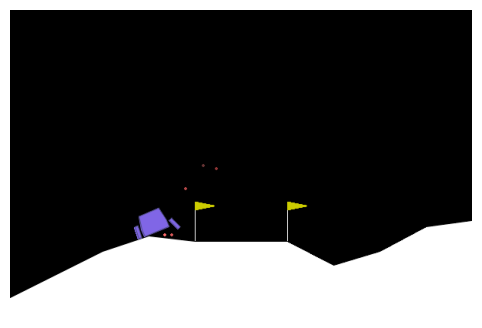

In [15]:
env = gym.make('LunarLander-v3',render_mode='rgb_array')


for episode in range(5):
    current_observation, info = env.reset()
    episode_over = False

    while not episode_over:
        action=env.action_space.sample()
        new_observation, reward, terminated, truncated, info = env.step(action)

        current_observation=new_observation
        episode_over = terminated or truncated


        #### Visualization ####
        frame = env.render()
        clear_output(wait=True)
        plt.figure(figsize=(6, 4))
        plt.imshow(frame)
        plt.axis('off')
        display(plt.gcf())
        plt.close()
        #### Visualization ####

env.close()


## Train an agent with deep Q-learning

### Definition of the hyperparameters and creation of an agent (and a new environment)

In [5]:
n_episodes=600
start_eps=1.0
batch_size=64
update_weights_period=1000


display_train=10

In [6]:
env = gym.make('LunarLander-v3')
env = gym.wrappers.RecordEpisodeStatistics(env, buffer_length=n_episodes)

agent=Agent_DQN(
    env=env,

    start_learning_rate=0.002,
    start_factor_lr=1.0,
    end_factor_lr=0.2,
    total_iters_lr=int(n_episodes/2),
    
    start_epsilon=start_eps,
    epsilon_decay = start_eps / (n_episodes/2),
    final_epsilon=0.1,
    gamma=0.99
    )

buffer = ReplayBuffer(capacity=100_000)

### Training loop

In [7]:
count_update=0
Training_loss=[]
Liste_epsilon=[]

for episode in range(n_episodes):
    current_observation, info = env.reset()
    episode_over = False

    while not episode_over:
        action=agent.eps_greedy_action(state=current_observation)
        new_observation, reward, terminated, truncated, info = env.step(action)
        buffer.add(current_observation, action, reward, new_observation, int(terminated))

        current_observation=new_observation
        episode_over = terminated or truncated


        if (len(buffer)>batch_size):
            count_update+=1

            # Liste_states,Liste_actions,Liste_rewards,Liste_next_states,Liste_terminated=buffer.sample(batch_size)
            # agent.update(
            #             Liste_states=Liste_states,
            #             Liste_actions=Liste_actions,
            #             Liste_rewards=Liste_rewards,
            #             Liste_next_states=Liste_next_states,
            #             Liste_terminated=Liste_terminated
            #             )

            # Update method is One batch of Gradient Descent 
            loss=agent.update(*buffer.sample(batch_size))


        if (count_update>update_weights_period):
            count_update=0

            # Load the new weights on the target network each update_weights_period
            agent.network_copy.load_state_dict(agent.main_network.state_dict())

    epsilon=agent.update_epsilon()
    agent.scheduler.step()

    Training_loss.append(loss)
    Liste_epsilon.append(epsilon)

    if (episode != 0 and episode%display_train==0):
        current_lr = agent.optimizer.param_groups[0]['lr']

        print(f"\nEpisode {episode} | LR = {current_lr:.6f}")
        print(f"Episode mean length: {np.array(env.length_queue)[-display_train:].mean()}")


agent.save_network("model_luner_lander")
stat_train_return=env.return_queue
stat_train_lenght=env.length_queue
env.close()
print("\nTraining done")


Episode 10 | LR = 0.001941
Episode mean length: 85.8

Episode 20 | LR = 0.001888
Episode mean length: 92.1

Episode 30 | LR = 0.001835
Episode mean length: 101.1

Episode 40 | LR = 0.001781
Episode mean length: 91.2

Episode 50 | LR = 0.001728
Episode mean length: 103.4

Episode 60 | LR = 0.001675
Episode mean length: 114.7

Episode 70 | LR = 0.001621
Episode mean length: 107.1

Episode 80 | LR = 0.001568
Episode mean length: 102.4

Episode 90 | LR = 0.001515
Episode mean length: 132.1

Episode 100 | LR = 0.001461
Episode mean length: 126.2

Episode 110 | LR = 0.001408
Episode mean length: 122.1

Episode 120 | LR = 0.001355
Episode mean length: 207.9

Episode 130 | LR = 0.001301
Episode mean length: 131.1

Episode 140 | LR = 0.001248
Episode mean length: 123.4

Episode 150 | LR = 0.001195
Episode mean length: 211.2

Episode 160 | LR = 0.001141
Episode mean length: 205.8

Episode 170 | LR = 0.001088
Episode mean length: 245.2

Episode 180 | LR = 0.001035
Episode mean length: 486.0

Epi

### Visualization of the training (copyright from Gymnasium)

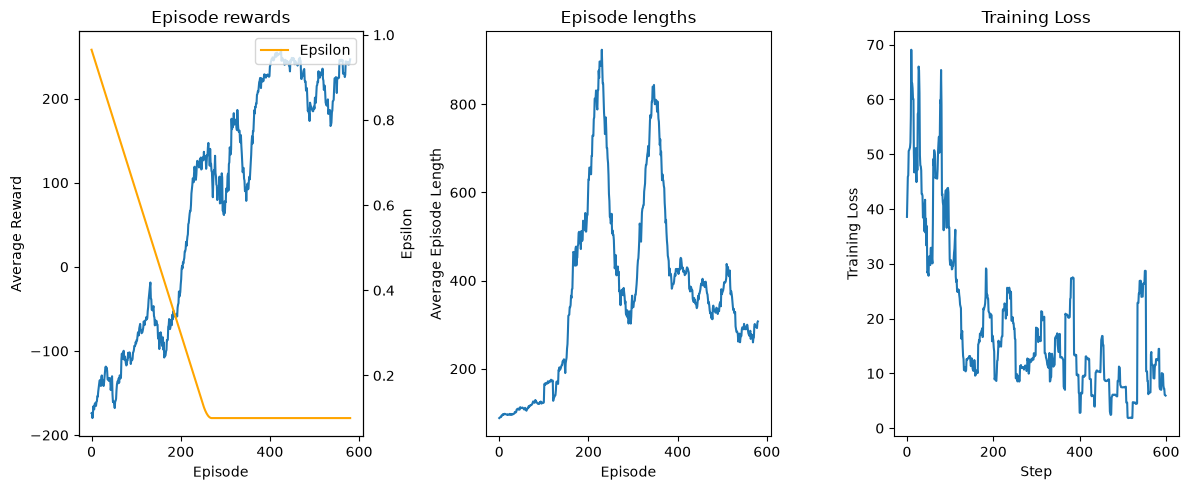

In [11]:

def get_moving_avgs(arr, window, convolution_mode):
    """Compute moving average to smooth noisy data."""
    return np.convolve(
        np.array(arr).flatten(),
        np.ones(window),
        mode=convolution_mode
    ) / window

# Smooth over a 500-episode window
rolling_length = display_train*2
fig, axs = plt.subplots(ncols=3, figsize=(12, 5))

# Episode rewards (win/loss performance)
axs[0].set_title("Episode rewards")
reward_moving_average = get_moving_avgs(
    stat_train_return,
    rolling_length,
    "valid"
)

epsilon_moving_avg=get_moving_avgs(
    Liste_epsilon,
    rolling_length,
    "valid"
)

x = range(len(reward_moving_average))
axs[0].plot(x, reward_moving_average, label="Average Reward")
axs[0].set_ylabel("Average Reward")
axs[0].set_xlabel("Episode")

# Axe Y droit : Epsilon
ax_epsilon = axs[0].twinx()
ax_epsilon.plot(x, epsilon_moving_avg, color="orange", label="Epsilon")
ax_epsilon.set_ylabel("Epsilon")
ax_epsilon.legend(loc="upper right")

# Episode lengths (how many actions per hand)
axs[1].set_title("Episode lengths")
length_moving_average = get_moving_avgs(
    stat_train_lenght,
    rolling_length,
    "valid"
)
axs[1].plot(range(len(length_moving_average)), length_moving_average)
axs[1].set_ylabel("Average Episode Length")
axs[1].set_xlabel("Episode")

# Training error (how much we're still learning)
axs[2].set_title("Training Loss")
training_loss_moving_average = get_moving_avgs(
    Training_loss,
    rolling_length,
    "same"
)
axs[2].plot(range(len(training_loss_moving_average)), training_loss_moving_average)
axs[2].set_ylabel("Training Loss")
axs[2].set_xlabel("Step")

plt.tight_layout()
plt.show()

## Let's test the agent !

### We load a new environment and we get a previous trained agent

In [12]:
env = gym.make('LunarLander-v3',render_mode='rgb_array')
agent_test=agent=Agent_DQN(
    env=env,

    start_learning_rate=None,
    start_factor_lr=None,
    end_factor_lr=None,
    total_iters_lr=None,
    
    start_epsilon=None,
    epsilon_decay = None,
    final_epsilon=None,
    gamma=None,
    main_neural_network_directory="models/model_luner_lander.pth")


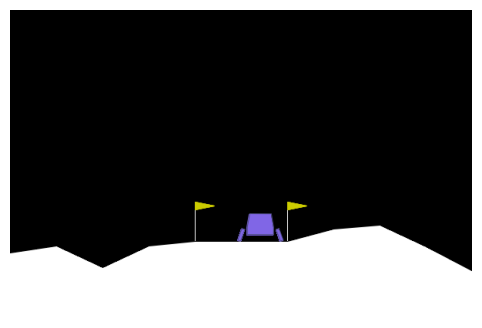

total_reward Episode 4: 262.4621586187767


In [14]:

for episode in range(5):
    current_observation, info = env.reset()

    episode_over = False
    total_reward = 0

    while not episode_over:
        action=agent_test.best_action(current_observation)
        new_observation, reward, terminated, truncated, info = env.step(action)

        current_observation=new_observation
        episode_over = terminated or truncated

        total_reward += reward

        #### Visualization ####
        frame = env.render()
        clear_output(wait=True)
        plt.figure(figsize=(6, 4))
        plt.imshow(frame)
        plt.axis('off')
        display(plt.gcf())
        plt.close()
        #### Visualization ####

    print(f"total_reward Episode {episode}:",total_reward)
    

env.close()



We note that the success of the landing is not garanteed but it is clearly better than the random policy.